# Staging and the significant increase in credit risk

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- compare the PD a loan had at origination with the PD it has at the reporting date on the same window, and annualise both so loans of different remaining life compare;
- apply the relative-and-absolute rule of significant increase in credit risk (SICR) with the threefold backstop, and say what each parameter of the policy does to the number of loans in Stage 2;
- allocate a stage with the 30 and 90 days past due presumptions, forbearance, the watch list and the low credit risk exemption, and read which trigger fired and why it took precedence;
- hold a cured loan in Stage 2 for a probation period, and report the target of a collective transfer without adding it to the allowance;
- read the stage flows and the coverage by stage of a committed reporting date, and compare a calm date with a stressed one.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C06 (SBA 7(a) small-business loans as the public twin of a mortgage book; U.S. Government Works, licence class `mirror-allowed`) at two reporting dates: 2008-12-31, in the financial crisis, and 2019-12-31, a calm year. Each artifact holds, besides the term structures of notebook 01:

- `outputs.settings.sicr`: the staging policy the pipeline used (the multiplier schedule, the absolute floor, the threefold ratio, the 30 and 90 days);
- `outputs.account_curves`: a sample of 40 accounts with their cumulative PD from origination and from the reporting date, quarter by quarter for three years;
- `outputs.sicr_points`: a sample of 400 accounts with their annualised PD at origination and now, the stage and the trigger the pipeline assigned;
- `outputs.stage_flows` and `outputs.stage_summary`: the movement of the whole book between the two year-end dates and its stage totals.

**What the file does not hold:** delinquency, forbearance or watch-list history (finding `F-NO-DELINQUENCY`). In C06 only the quantitative SICR test can move a loan to Stage 2, and the days past due are zero. The cases of the qualitative triggers below are therefore **constructed accounts**, labelled as such, to show how the engine decides.

The next cell loads both artifacts, builds the engine's `StagingPolicy` from the committed settings and prints the policy and the engine versions.

In [2]:
# Load the two reporting dates and build the engine's staging policy from the committed settings
from riskvalidation.provisions import staging, term_structure as tsm

ROOT = Path("../../..").resolve()
LANG = "en"


def read(name):
    return json.loads((ROOT / "data" / "derived" / "C06" / name).read_text(encoding="utf-8"))


crisis, calm = read("rd-2008-12.json"), read("rd-2019-12.json")
out = crisis["outputs"]
sicr = out["settings"]["sicr"]
policy = staging.StagingPolicy(
    multiplier_schedule=tuple((row["pd_origination_upper"], row["multiplier"]) for row in sicr["multiplier_schedule"]),
    absolute_floor=sicr["absolute_floor"], threefold_ratio=sicr["threefold_ratio"],
    dpd_backstop=sicr["dpd_backstop"], default_dpd=sicr["default_dpd"],
    probation_months=out["settings"]["probation_months"], low_credit_risk_pd=sicr["low_credit_risk_pd"],
)
print("multiplier schedule (origination PD up to, multiplier):", policy.multiplier_schedule)
print("absolute floor:", policy.absolute_floor, "| threefold ratio:", policy.threefold_ratio, "| dpd:", policy.dpd_backstop, policy.default_dpd)
print("baked by engine:", crisis["provenance"]["riskvalidation_version"], calm["provenance"]["riskvalidation_version"], "| installed engine:", md.version("riskvalidation"))
print("finding:", [f["title"][LANG] for f in crisis["findings"] if f["id"] == "F-NO-DELINQUENCY"][0])

multiplier schedule (origination PD up to, multiplier): ((0.01, 4.0), (0.05, 2.5), (0.5, 1.5))
absolute floor: 0.005 | threefold ratio: 3.0 | dpd: 30 90
baked by engine: 1.0.1 1.0.1 | installed engine: 1.0.1
finding: The SBA file has no delinquency, forbearance or watch-list history: only the quantitative SICR test can move a loan to Stage 2, and Stage 3 holds no balance at a date


## Method

The staging of IFRS 9 compares the credit risk now with the risk at initial recognition (IFRS 9 5.5.3, 5.5.9). The standard does not prescribe how. Contraste follows the practice its research found (GPPC 2016, section 2.7.2; BCBS d350, annex A26; EBA/Rep/2021/35 and EBA/Rep/2023/36 paragraph 32). Four elements:

**1. The same window.** The origination expectation for the remaining window is the forward PD from the term structure estimated at origination, $PD^{\mathrm{orig}}(a, a+H) = \frac{S^{(t_0)}(a) - S^{(t_0)}(a+H)}{S^{(t_0)}(a)}$, and the current estimate is $PD^{\mathrm{rep}}(0, H)$ from the term structure at the reporting date. Both are annualised so that loans of different remaining life compare: $\overline{PD} = 1 - (1 - PD)^{1/H_{\mathrm{yrs}}}$. The geometric form is Contraste's documented convention; the EBA states that it compares annualised lifetime PDs and, in the passages read, does not state the formula (UNVERIFIED as the EBA's).

**2. The quantitative rule** (relative and absolute, with the threefold backstop), with $m(\cdot)$ a multiplier that does not rise with the origination PD and $\delta$ an absolute floor:

$$\mathrm{SICR} = \mathbb{1}\Bigl[\tfrac{\overline{PD}^{\mathrm{rep}}}{\overline{PD}^{\mathrm{orig}}} \ge m(\overline{PD}^{\mathrm{orig}}) \;\wedge\; \overline{PD}^{\mathrm{rep}} - \overline{PD}^{\mathrm{orig}} \ge \delta\Bigr] \;\vee\; \mathbb{1}\Bigl[\tfrac{\overline{PD}^{\mathrm{rep}}}{\overline{PD}^{\mathrm{orig}}} \ge 3\Bigr]$$

**3. The stage.** Stage 3 if the loan is in default (defaulted, or 90 or more days past due, B5.5.37); otherwise Stage 2 if any trigger fires (more than 30 days past due as a rebuttable presumption, 5.5.11; forbearance; watch list; a collective transfer; the quantitative rule); otherwise Stage 1. The low credit risk exemption (5.5.10) suppresses only the two quantitative triggers. The engine states the precedence of the triggers and returns the one that decided.

**4. The way back and the collective view.** A loan that is back in Stage 1 is held in Stage 2 for a probation period (B5.5.27, a policy parameter, not a number of the standard). When a risk driver is known only for a segment, a share $\pi_g$ of the segment is moved to Stage 2: $\mathrm{amount}_g = \pi_g \sum_{i \in g} \mathrm{GCA}_i$ (B5.5.6).

The thresholds are Contraste's configurable policy, not regulation: the threefold ratio is a supervisory expectation (EBA/Rep/2023/36 paragraph 32), not IFRS 9.

### Step 1: origination against the reporting date, on the same window

The artifact keeps, for 40 accounts, the cumulative PD over the first three years from origination and from the reporting date. We take a Stage 1 account and a Stage 2 account, convert each cumulative PD at month 36 into an annualised PD with `annualise_pd` over the 3 years, and ask `sicr_quantitative` whether the pair is a significant increase under the committed policy. The window is the three years the artifact keeps for both curves, which is the point: the two PDs refer to the same window.

In [3]:
# Annualise the origination and the current cumulative PD of a Stage 1 and a Stage 2 account and test them
curves = {c["account_id"]: c for c in out["account_curves"]}
stage1_id = next(a for a, c in curves.items() if c["stage"] == "stage1")
stage2_id = next(a for a, c in curves.items() if c["stage"] == "stage2")

for account_id in (stage1_id, stage2_id):
    c = curves[account_id]
    cum_orig, cum_now = c["origination_cumulative_pd"][-1], c["current_cumulative_pd"][-1]
    ann_orig = float(tsm.annualise_pd(np.array([cum_orig]), 3.0)[0])
    ann_now = float(tsm.annualise_pd(np.array([cum_now]), 3.0)[0])
    flagged = bool(staging.sicr_quantitative(np.array([ann_orig]), np.array([ann_now]), policy)[0])
    print(account_id, c["segment_id"], "| stage in the artifact:", c["stage"])
    print("   cumulative PD at 36 months, origination and now:", round(cum_orig, 6), round(cum_now, 6))
    print("   annualised PD, origination and now:", round(ann_orig, 6), round(ann_now, 6), "| ratio:", round(ann_now / ann_orig, 3), "| difference:", round(ann_now - ann_orig, 6))
    print("   significant increase under the policy:", flagged)

A0001 term-gt-240 | stage in the artifact: stage1
   cumulative PD at 36 months, origination and now: 0.008564 0.010189
   annualised PD, origination and now: 0.002863 0.003408 | ratio: 1.19 | difference: 0.000545
   significant increase under the policy: False
A0005 term-61-120 | stage in the artifact: stage2
   cumulative PD at 36 months, origination and now: 0.033812 0.089148
   annualised PD, origination and now: 0.0114 0.030646 | ratio: 2.688 | difference: 0.019246
   significant increase under the policy: True


### Step 2: the rule on 400 accounts

`sicr_points` holds the annualised PDs of 400 accounts and the stage and trigger the pipeline assigned with `allocate_stages`. We pass the PDs to `allocate_stages` with zero days past due and no qualitative flag (the file has none) and compare the stage and the trigger with the committed ones. The comparison is a reconciliation: if the engine installed now and the engine that baked the artifact agreed on every account, the counts are equal.

In [4]:
# Allocate the stages of the 400 sampled accounts and compare them with the committed stage and trigger
points = out["sicr_points"]
orig = np.array([p["pd_origination_annualised"] for p in points])
now = np.array([p["pd_current_annualised"] for p in points])
n = len(points)
zeros, none = np.zeros(n, dtype=np.int64), np.zeros(n, dtype=bool)
result = staging.allocate_stages(orig, now, zeros, none, none, none, policy)

stage_name = {1: "stage1", 2: "stage2", 3: "stage3"}
same_stage = all(stage_name[int(s)] == p["stage"] for s, p in zip(result.stage, points))
same_trigger = all(str(t) == p["trigger"] for t, p in zip(result.trigger, points))
print("accounts:", n, "| same stage as the artifact:", same_stage, "| same trigger:", same_trigger)
for trigger in sorted({str(t) for t in result.trigger}):
    print("trigger", trigger, ":", int(np.sum(result.trigger == trigger)))
print("share in Stage 2:", round(float(np.mean(result.stage == 2)), 4), "| engine versions, baked and installed:", crisis["provenance"]["riskvalidation_version"], md.version("riskvalidation"))
print("annualised PD range, origination:", round(float(orig.min()), 5), round(float(orig.max()), 5))

accounts: 400 | same stage as the artifact: True | same trigger: True
trigger none : 384
trigger relative-absolute : 16
share in Stage 2: 0.04 | engine versions, baked and installed: 1.0.1 1.0.1
annualised PD range, origination: 0.00104 0.15679


### Step 3: what each parameter of the policy does

A validator asks how many loans move when a parameter moves. The cell reruns `sicr_quantitative` on the same 400 accounts with the absolute floor $\delta$ set to 0, 0.005 (the committed value), 0.01 and 0.02, with the threefold ratio set to 2, 3 and 5, and with the whole multiplier schedule scaled by 0.75, 1 and 1.25. Everything else stays as committed. The policy is an immutable dataclass: `dataclasses.replace` makes a new one and leaves the committed policy alone.

In [5]:
# Count the loans flagged under a grid of floors, threefold ratios and multiplier scales on the same accounts
print("committed policy:", int(staging.sicr_quantitative(orig, now, policy).sum()), "flagged of", n)
for floor in (0.0, 0.005, 0.01, 0.02):
    flagged = staging.sicr_quantitative(orig, now, dataclasses.replace(policy, absolute_floor=floor))
    print("absolute floor", floor, "->", int(flagged.sum()))
for ratio in (2.0, 3.0, 5.0):
    flagged = staging.sicr_quantitative(orig, now, dataclasses.replace(policy, threefold_ratio=ratio))
    print("threefold ratio", ratio, "->", int(flagged.sum()))
for scale in (0.75, 1.0, 1.25):
    scaled = dataclasses.replace(policy, multiplier_schedule=tuple((upper, mult * scale) for upper, mult in policy.multiplier_schedule))
    print("multipliers scaled by", scale, "->", int(staging.sicr_quantitative(orig, now, scaled).sum()))
ratios = now / orig
print("largest ratio of the sample:", round(float(ratios.max()), 3), "| accounts at three times or more:", int((ratios >= 3.0).sum()))

committed policy: 16 flagged of 400
absolute floor 0.0 -> 16
absolute floor 0.005 -> 16
absolute floor 0.01 -> 16
absolute floor 0.02 -> 15
threefold ratio 2.0 -> 35
threefold ratio 3.0 -> 16
threefold ratio 5.0 -> 16
multipliers scaled by 0.75 -> 109
multipliers scaled by 1.0 -> 16
multipliers scaled by 1.25 -> 2
largest ratio of the sample: 2.764 | accounts at three times or more: 0


### Step 4: the presumptions, the exemption and the precedence on constructed accounts

The next cell builds seven accounts by hand, one for each rule, and gives each the same pair of PDs (a quiet pair that the quantitative rule does not flag) except the last, which has a tripled PD. It then lets `allocate_stages` decide. The point is the order: a defaulted account is Stage 3 whatever else is true; 31 days past due is Stage 2 even when the PDs are quiet; forbearance and the watch list are Stage 2; an account with several reasons gets the trigger of highest precedence. These accounts are **constructed to show the rule**; they are not data.

In [6]:
# Seven constructed accounts, one rule each, and the stage and trigger the engine assigns
labels = ["quiet", "30 days past due", "31 days past due", "90 days past due",
          "forborne", "watch list and 31 days", "PD tripled"]
pd_orig = np.full(7, 0.02)
pd_now = np.array([0.021, 0.021, 0.021, 0.021, 0.021, 0.021, 0.061])
dpd = np.array([0, 30, 31, 90, 0, 31, 0])
forborne = np.array([False, False, False, False, True, False, False])
watch = np.array([False, False, False, False, False, True, False])
defaulted = np.zeros(7, dtype=bool)
built = staging.allocate_stages(pd_orig, pd_now, dpd, forborne, watch, defaulted, policy)
for label, stage, trigger in zip(labels, built.stage, built.trigger):
    print(f"{label:34s} -> stage {int(stage)} | trigger: {trigger}")

quiet                              -> stage 1 | trigger: none
30 days past due                   -> stage 1 | trigger: none
31 days past due                   -> stage 2 | trigger: dpd-backstop
90 days past due                   -> stage 3 | trigger: default
forborne                           -> stage 2 | trigger: forbearance
watch list and 31 days             -> stage 2 | trigger: dpd-backstop
PD tripled                         -> stage 2 | trigger: relative-absolute


The low credit risk exemption (5.5.10) lets an institution keep in Stage 1 a loan whose credit risk is low at the reporting date, even if it rose. It is a policy parameter, `low_credit_risk_pd`, and it suppresses only the two quantitative triggers, never the days past due or forbearance (5.5.11, B5.5.37). The cell sets it to 0.03 and reruns the same accounts: the tripled PD of the last account, 0.061, is above it and stays in Stage 2, so we add one more account, whose PD rose from 0.002 to 0.0082 (a rise of four times, under the exemption cut-off) to show the exemption at work. `lcr_exempt` says which accounts would have been flagged without it.

In [7]:
# Rerun with a low credit risk cut-off and add an account that is exempt, to see what the exemption suppresses
exempt_policy = dataclasses.replace(policy, low_credit_risk_pd=0.03)
pd_orig8 = np.append(pd_orig, 0.002)
pd_now8 = np.append(pd_now, 0.0082)
args = (np.append(dpd, 0), np.append(forborne, False), np.append(watch, False), np.append(defaulted, False))
without = staging.allocate_stages(pd_orig8, pd_now8, *args, policy)
with_exemption = staging.allocate_stages(pd_orig8, pd_now8, *args, exempt_policy)
for k in (6, 7):
    print("account", k + 1, "| without the exemption:", int(without.stage[k]), without.trigger[k], "| with it:", int(with_exemption.stage[k]), with_exemption.trigger[k], "| lcr_exempt:", bool(with_exemption.lcr_exempt[k]))
print("days past due and forbearance are untouched:", bool(np.all(with_exemption.stage[:6] == without.stage[:6])))

account 7 | without the exemption: 2 relative-absolute | with it: 2 relative-absolute | lcr_exempt: False
account 8 | without the exemption: 2 relative-absolute | with it: 1 none | lcr_exempt: True
days past due and forbearance are untouched: True


### Step 5: the way back (probation) and the collective transfer

`apply_cure_probation` holds in Stage 2 an account that is Stage 1 now, was Stage 2 before and cured fewer than `probation_months` ago. The committed C06 policy has no probation (the file has no cure dates and the reporting dates are a year apart), so the cell uses a probation of 12 months on three constructed accounts that cured 3, 12 and 20 months ago. `collective_transfer` reports, for each segment, the money that the collective view would move to Stage 2, $\pi_g \sum \mathrm{GCA}$. It only reports: the amount never enters an allowance, the caller turns it into accounts and the ECL reaches the allowance through their stage.

In [8]:
# Hold cured accounts in Stage 2 for a probation period and report a collective transfer target
probation_policy = dataclasses.replace(policy, probation_months=12)
stage_now = np.array([1, 1, 1])
stage_before = np.array([2, 2, 2])
months_since_cure = np.array([3, 12, 20])
now_result = staging.allocate_stages(np.full(3, 0.02), np.full(3, 0.021), np.zeros(3, dtype=np.int64), np.zeros(3, dtype=bool), np.zeros(3, dtype=bool), np.zeros(3, dtype=bool), probation_policy)
held = staging.apply_cure_probation(stage_now, stage_before, months_since_cure, probation_policy, now_result)
for m_, s_, t_ in zip(months_since_cure, held.stage, held.trigger):
    print("cured months ago", int(m_), "-> stage", int(s_), "|", t_)

gross = np.array([1_000_000.0, 3_000_000.0, 2_000_000.0, 4_000_000.0])
segments = np.array(["A", "A", "B", "B"])
target = staging.collective_transfer(gross, segments, {"A": 0.10, "B": 0.25})
print("collective target by segment:", target)

cured months ago 3 -> stage 2 | cure-probation
cured months ago 12 -> stage 1 | none
cured months ago 20 -> stage 1 | none
collective target by segment: {'A': 400000.0, 'B': 1500000.0}


### Step 6: the stage flows and the coverage by stage, in a crisis and in a calm year

The committed artifact reports the movement of the whole book between the two year-end dates, in accounts and gross carrying amount, and the allowance and coverage by stage at the end. This is what an IFRS 7 disclosure needs. The cell reads the flows of 2008, computes the share of the opening Stage 1 accounts that moved to Stage 2 in the year, prints the stage summary of both dates and the coverage of Stage 2 over Stage 1. Notebook 04 closes the roll-forward of the allowance.

In [9]:
# Read the stage flows of the crisis year and the stage summary of both reporting dates
flows = out["stage_flows"]["flows"]
opening_stage1 = sum(f["accounts"] for f in flows if f["source"] == "stage1")
to_stage2 = sum(f["accounts"] for f in flows if f["source"] == "stage1" and f["target"] == "stage2")
print("flows between", out["stage_flows"]["from_date"], "and", out["stage_flows"]["to_date"])
for f in flows:
    print(f"{f['source']:9s} -> {f['target']:12s} accounts: {f['accounts']:7d} | gross carrying amount (USD millions): {f['gross_carrying_amount'] / 1e6:10.1f}")
print("opening Stage 1 accounts:", opening_stage1, "| moved to Stage 2:", to_stage2, "| share:", round(to_stage2 / opening_stage1, 4))

for name, art in (("2008-12-31", crisis), ("2019-12-31", calm)):
    rows = {r["stage"]: r for r in art["outputs"]["stage_summary"]["rows"]}
    total_gca = sum(r["gross_carrying_amount"] for r in rows.values())
    print(name, "| accounts by stage:", [rows[s]["accounts"] for s in ("stage1", "stage2", "stage3")], "| coverage by stage:", [round(rows[s]["coverage"], 4) for s in ("stage1", "stage2", "stage3")], "| Stage 2 share of the gross amount:", round(rows["stage2"]["gross_carrying_amount"] / total_gca, 5))
rows = {r["stage"]: r for r in out["stage_summary"]["rows"]}
print("coverage of Stage 2 over Stage 1, 2008:", round(rows["stage2"]["coverage"] / rows["stage1"]["coverage"], 3))

flows between 2007-12-31 and 2008-12-31
new       -> stage1       accounts:   48388 | gross carrying amount (USD millions):     9351.8
new       -> stage2       accounts:    1119 | gross carrying amount (USD millions):       67.8
stage1    -> derecognised accounts:   50962 | gross carrying amount (USD millions):     5017.5
stage1    -> stage1       accounts:  249589 | gross carrying amount (USD millions):    37364.5
stage1    -> stage2       accounts:   12407 | gross carrying amount (USD millions):      463.6
stage1    -> written-off  accounts:   12773 | gross carrying amount (USD millions):      908.8
stage2    -> derecognised accounts:     129 | gross carrying amount (USD millions):        4.8
stage2    -> written-off  accounts:      88 | gross carrying amount (USD millions):        3.0
opening Stage 1 accounts: 325731 | moved to Stage 2: 12407 | share: 0.0381
2008-12-31 | accounts by stage: [297977, 13526, 0] | coverage by stage: [0.0171, 0.1297, 0.0] | Stage 2 share of the gross am

### Step 7: the accounts, the rule and the book, drawn

The left panel plots the 400 accounts by their annualised PD at origination (horizontal) and now (vertical), on logarithmic axes, coloured by the stage the engine assigned. The line of equal PD and the threefold line bound the region where the quantitative rule can act; the accounts above the multiplier of their origination PD and the absolute floor are Stage 2. The right panel shows the coverage (allowance over gross carrying amount) by stage on 2008-12-31.

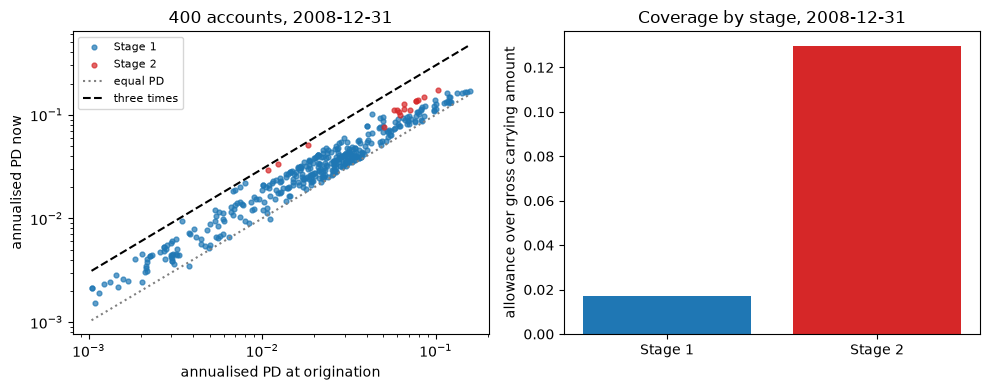

In [10]:
# Draw the 400 accounts by origination and current annualised PD, and the coverage by stage
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
for stage_no, color in ((1, "tab:blue"), (2, "tab:red")):
    mask = result.stage == stage_no
    left.scatter(orig[mask], now[mask], s=12, color=color, alpha=0.7, label="Stage " + str(stage_no))
grid = np.array([orig.min(), orig.max()])
left.plot(grid, grid, color="grey", linestyle=":", label="equal PD")
left.plot(grid, 3.0 * grid, color="black", linestyle="--", label="three times")
left.set_xscale("log")
left.set_yscale("log")
left.set_xlabel("annualised PD at origination")
left.set_ylabel("annualised PD now")
left.set_title("400 accounts, 2008-12-31")
left.legend(fontsize=8)

names = ["Stage 1", "Stage 2"]
right.bar(names, [rows["stage1"]["coverage"], rows["stage2"]["coverage"]], color=["tab:blue", "tab:red"])
right.set_ylabel("allowance over gross carrying amount")
right.set_title("Coverage by stage, 2008-12-31")
fig.tight_layout()
plt.show()

## Results

- **Two accounts, one rule.** The Stage 1 account A0001 has an annualised PD of 0.0029 at origination and 0.0034 now, a ratio of 1.19: no significant increase. The Stage 2 account A0005 goes from 0.0114 to 0.0306, a ratio of 2.69 and a difference of 0.0192: its origination PD falls in the band whose multiplier is 2.5, so the ratio and the floor are both met.
- **The engine reproduces the committed staging.** On the 400 sampled accounts the stage and the trigger of `allocate_stages` equal the committed ones: 384 accounts in Stage 1 and 16 in Stage 2, all 16 by the relative-and-absolute rule (4% of the sample). The artifact was baked with engine 0.5.0; the engine installed now (0.8.1) gives the same allocation, which is the reconciliation the check performs.
- **The threefold backstop never acts here.** The largest ratio in the sample is 2.76, so no account is at three times or more, and the threefold ratio changes the count only when it is lowered to 2 (35 accounts). The absolute floor hardly matters either: the count is 16 for a floor of 0, 0.005 and 0.01 and 15 for 0.02.
- **The multiplier schedule is the lever.** Scaling the whole schedule by 0.75 moves 109 accounts to Stage 2, by 1.25 only 2. This is the quantity a validator has to challenge, together with its calibration to the origination PD, and the threshold must not loosen when conditions worsen (EBA/Rep/2023/36 paragraph 33).
- **The qualitative rules are exact at their boundaries.** 30 days past due is Stage 1 and 31 is Stage 2 by the backstop; 90 is Stage 3; forbearance is Stage 2; when two reasons hold, the trigger of higher precedence is the one reported (the watch list with 31 days is reported as `dpd-backstop`). The low credit risk exemption suppressed the relative-and-absolute trigger of the account whose PD rose from 0.002 to 0.0082 and left every days-past-due and forbearance case alone.
- **Probation and the collective view.** With a probation of 12 months, the account cured 3 months ago stays in Stage 2 with trigger `cure-probation`, and the ones cured 12 and 20 months ago return to Stage 1. The collective target is 400,000 for segment A (10% of 4,000,000) and 1,500,000 for segment B (25% of 6,000,000): amounts to turn into accounts, never to add to the allowance.
- **A crisis year and a calm year.** In 2008, 12,407 of the 325,731 opening Stage 1 accounts (3.81%) moved to Stage 2, Stage 2 held 1.1% of the gross amount and its coverage was 12.97% against 1.71% for Stage 1, 7.59 times higher. On 2019-12-31 no loan was in Stage 2 and the coverage of Stage 1 was 0.58%.

What this notebook does not show: the pipeline stages loans with the quantitative rule only, because the file has no delinquency history (finding `F-NO-DELINQUENCY`), so Stage 3 holds no balance at a date and the days-past-due cases are constructed. The 400 accounts are a sample, and the stage flows and summaries are those of the whole book. Whether the staging predicts defaults is a validation question, answered in notebook 05.

## Summary

- Staging compares the PD now with the PD at origination on the same window, both annualised, and the engine applies a relative-and-absolute rule with a threefold backstop; the parameters are policy, not regulation.
- `allocate_stages` returns the stage and the trigger that decided, with a fixed precedence: default, days past due, forbearance, watch list, collective, relative-and-absolute, threefold. The low credit risk exemption touches only the two quantitative triggers.
- On C06 at the crisis date the pipeline's staging is reproduced exactly, 16 of 400 sampled accounts in Stage 2, and the multiplier schedule, not the floor or the threefold ratio, decides how many.
- Probation and the collective transfer are separate functions: the first holds a cured loan in Stage 2, the second only reports a target amount.
- The stage flows and the coverage by stage are what an IFRS 7 table needs: Stage 2 coverage was 7.59 times that of Stage 1 in 2008, and there was no Stage 2 in 2019.

**What to try next.** Change `probation_months` to 6 and to 24, scale the multiplier schedule by 0.5 (the engine will refuse it: multipliers must be at least 1), and read the message. Then continue with notebook 03, which weights the scenarios behind these PDs.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- EBA (2021), IFRS 9 implementation by EU institutions, monitoring report, EBA/Rep/2021/35. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2021/1024609/IFRS9%20monitoring%20report.pdf
- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- Botha, A. and Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, equations 6 to 10. https://arxiv.org/abs/2507.15441